# SHL Grammar Scoring Engine

## Problem Statement
Build a **Grammar Scoring Engine** for spoken audio samples. Given an audio file (.wav, 45-60 seconds), predict a continuous grammar quality score ranging from **0 to 5** based on the MOS Likert Grammar Score rubric.

## Approach Overview
The pipeline follows a three-stage architecture:

1. **Speech-to-Text (ASR)**: Transcribe audio using OpenAI Whisper (base model)
2. **Feature Engineering**: Extract 75 features from both transcripts (text) and audio signals
   - **Text Features** (32): Grammar errors, vocabulary richness, sentence structure, fluency indicators
   - **Audio Features** (43): MFCCs, pitch, energy, speaking rate, pause patterns
3. **Regression Model**: Train an ensemble of XGBoost and LightGBM to predict grammar scores

## Evaluation Metrics
- **Pearson Correlation Coefficient** — measures linear correlation between predictions and ground truth
- **RMSE (Root Mean Squared Error)** — measures prediction error magnitude


## 1. Setup & Imports

In [1]:
import os
import json
import re
import warnings
warnings.filterwarnings('ignore')

# Set environment variable for OpenMP compatibility on macOS
os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# ML
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import Ridge
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

# Audio
import librosa
import soundfile as sf

# Set plot style
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('viridis')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 12

print("Setup complete!")


Setup complete!


## 2. Data Loading & Exploration

In [2]:
# Load CSV data
train_df = pd.read_csv('Dataset_Final/train.csv')
test_df = pd.read_csv('Dataset_Final/test.csv')

print(f"Training set: {len(train_df)} samples")
print(f"Test set: {len(test_df)} samples")
print(f"\nTraining data preview:")
train_df.head(10)


Training set: 769 samples
Test set: 216 samples

Training data preview:


,filename,label
0,audio_192.wav,3.0
1,audio_436.wav,3.0
2,audio_447.wav,3.5
3,audio_126.wav,2.0
4,audio_61.wav,2.0
5,audio_639.wav,2.5
6,audio_703.wav,2.0
7,audio_509.wav,3.0
8,audio_672.wav,4.0
9,audio_344.wav,4.0


In [3]:
# Label distribution analysis
print("Label Statistics:")
print(train_df['label'].describe())
print(f"\nUnique scores: {sorted(train_df['label'].unique())}")
print(f"Score value counts:")
print(train_df['label'].value_counts().sort_index())


Label Statistics:
count    769.000000
mean       3.313394
std        1.239000
min        0.000000
25%        2.500000
50%        3.000000
75%        4.000000
max        5.000000
Name: label, dtype: float64

Unique scores: [np.float64(0.0), np.float64(1.0), np.float64(1.5), np.float64(2.0), np.float64(2.5), np.float64(3.0), np.float64(3.5), np.float64(4.0), np.float64(4.5), np.float64(5.0)]
Score value counts:
label
0.0     37
1.0      1
1.5      3
2.0    102
2.5     79
3.0    174
3.5     64
4.0    124
4.5     52
5.0    133
Name: count, dtype: int64


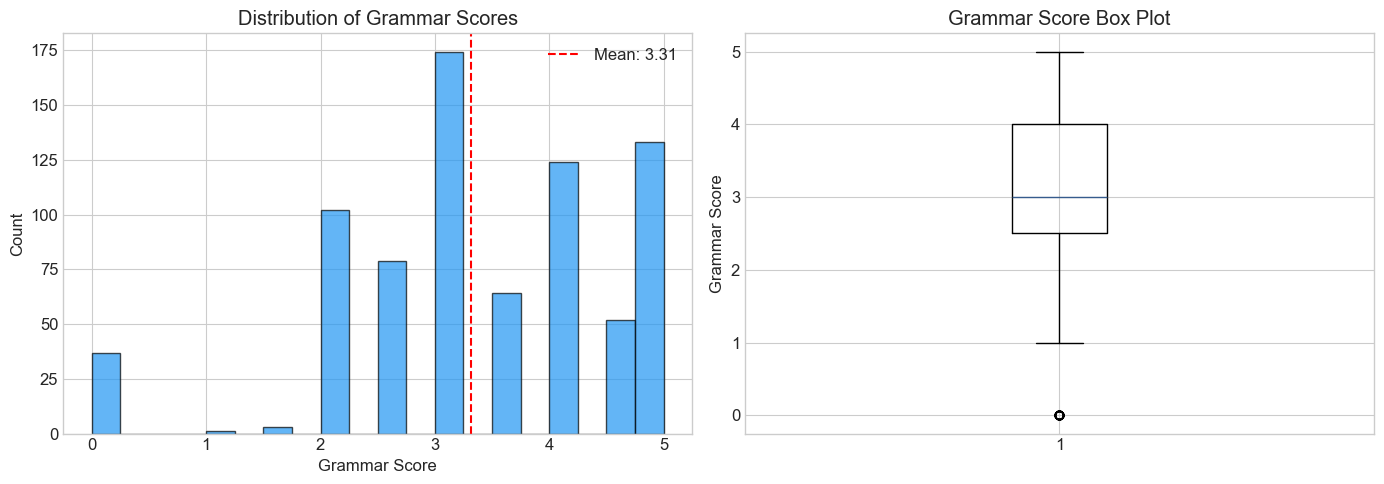

Mean score: 3.31, Std: 1.24


In [4]:
# Visualize label distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram
axes[0].hist(train_df['label'], bins=20, edgecolor='black', alpha=0.7, color='#2196F3')
axes[0].set_xlabel('Grammar Score')
axes[0].set_ylabel('Count')
axes[0].set_title('Distribution of Grammar Scores')
axes[0].axvline(train_df['label'].mean(), color='red', linestyle='--',
                label=f"Mean: {train_df['label'].mean():.2f}")
axes[0].legend()

# Box plot
axes[1].boxplot(train_df['label'], vert=True)
axes[1].set_ylabel('Grammar Score')
axes[1].set_title('Grammar Score Box Plot')

plt.tight_layout()
plt.savefig('label_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
print(f"Mean score: {train_df['label'].mean():.2f}, Std: {train_df['label'].std():.2f}")


In [5]:
# Audio file analysis
durations = []
for filename in train_df['filename'][:50]:  # Sample 50 files for speed
    path = f'Dataset_Final/train/{filename}'
    y, sr = librosa.load(path, sr=16000, duration=None)
    durations.append(len(y) / sr)

print(f"Audio duration statistics (sample of 50):")
print(f"  Mean: {np.mean(durations):.1f}s")
print(f"  Min:  {np.min(durations):.1f}s")
print(f"  Max:  {np.max(durations):.1f}s")
print(f"  Std:  {np.std(durations):.1f}s")


Audio duration statistics (sample of 50):
  Mean: 54.9s
  Min:  26.5s
  Max:  60.5s
  Std:  8.1s


## 3. Audio Transcription (Whisper ASR)

We use OpenAI's **Whisper base** model to transcribe all audio files to text. Whisper is a robust, general-purpose speech recognition model trained on 680,000 hours of multilingual data.

**Why Whisper base?**
- Good balance of speed and accuracy
- Handles accented English well
- Provides word-level timestamps for pause analysis

Transcripts were pre-computed using `transcribe_audio.py` to save time.


In [6]:
# Load pre-computed transcripts
with open('transcripts/train_transcripts.json', 'r') as f:
    train_transcripts = json.load(f)
with open('transcripts/test_transcripts.json', 'r') as f:
    test_transcripts = json.load(f)

print(f"Train transcripts loaded: {len(train_transcripts)}")
print(f"Test transcripts loaded: {len(test_transcripts)}")

# Check for empty transcripts
empty_count = sum(1 for v in train_transcripts.values() if not v['text'].strip())
print(f"Empty transcripts in train: {empty_count}")

# Show sample transcripts with their scores
print("\n" + "="*80)
print("SAMPLE TRANSCRIPTS")
print("="*80)
for idx, row in train_df.head(3).iterrows():
    fname = row['filename']
    score = row['label']
    text = train_transcripts.get(fname, {}).get('text', 'N/A')
    print(f"\n[Score: {score}] {fname}")
    print(f"  {text[:200]}...")


Train transcripts loaded: 769
Test transcripts loaded: 216
Empty transcripts in train: 7

SAMPLE TRANSCRIPTS

[Score: 3.0] audio_192.wav
   Well, this petite land is very, very beautiful and fun. There are fleets like the navy around the swing. The swing usually enjoys this swing. It has to be like, it's more like a game of play. Because...

[Score: 3.0] audio_436.wav
   To see no of a school playground, our playground looks like a very big playground having a more more greenery trees in which we students like to garden a more trees to have a fresh year and all havin...

[Score: 3.5] audio_447.wav
   I favorite place to visit is the beach. I love the sound of the waves crashing against the shore. The feeling of the sand between my toys and the small, is my love, the saltwater. I love the fact tha...


In [7]:
# Show examples across different score ranges
print("Examples by score range:")
print("="*80)
for score_range in [(0, 1.5), (2, 2.5), (3, 3.5), (4, 4.5), (5, 5)]:
    subset = train_df[(train_df['label'] >= score_range[0]) & (train_df['label'] <= score_range[1])]
    if len(subset) > 0:
        sample = subset.iloc[0]
        text = train_transcripts.get(sample['filename'], {}).get('text', 'N/A')
        print(f"\n[Score: {sample['label']}] {sample['filename']}")
        print(f"  {text[:250]}")
        print()


Examples by score range:

[Score: 0.0] audio_5055.wav
   first of One next thing. This is how I felt so free to abandon it. Every time I look at you, you will be my friend. I feel make me feel further, I feel further, ever again. Into an up-to-date, I just flatten my heart to a half-two-three and let's do


[Score: 2.0] audio_126.wav
   Once upon a time, we, with five friends, went on a tube, went on a deep tour with a driver agent on a monolith and we stayed on a resort and we stayed around we stayed at a resort and after that, when we checked in in the resort after that night we 


[Score: 3.0] audio_192.wav
   Well, this petite land is very, very beautiful and fun. There are fleets like the navy around the swing. The swing usually enjoys this swing. It has to be like, it's more like a game of play. Because once it's in it and the other thing, we'll have t


[Score: 4.0] audio_672.wav
   The school playground is very big and is very colorful. It has a lot of games for kids. And these

## 4. Feature Engineering

We extract **75 features** from each audio sample across two categories:

### Text Features (32 features)
- **Vocabulary**: word count, unique words, type-token ratio, avg word length
- **Sentence Structure**: sentence count, avg/std/max/min sentence length
- **Complexity**: syllables per word, complex word ratio, conjunction usage
- **Fluency**: filler words, repetitions
- **Grammar**: error count, error rate, error types (via LanguageTool)
- **Parts of Speech**: pronouns, articles, prepositions, conjunctions

### Audio Features (43 features)
- **Energy**: RMS mean/std/max
- **Temporal**: duration, silence ratio, speaking rate, pause patterns
- **Spectral**: spectral centroid, MFCCs (13 coefficients x mean+std)
- **Voice Quality**: zero crossing rate, pitch mean/std/range


In [8]:
from feature_extraction import extract_text_features, extract_audio_features, extract_all_features

# Extract features for training data
print("Extracting training features...")
train_features_df = extract_all_features(
    train_df, train_transcripts, 'Dataset_Final/train', use_grammar_tool=True
)
print(f"Training features shape: {train_features_df.shape}")

# Extract features for test data
print("\nExtracting test features...")
test_features_df = extract_all_features(
    test_df, test_transcripts, 'Dataset_Final/test', use_grammar_tool=True
)
print(f"Test features shape: {test_features_df.shape}")


Extracting training features...
Initializing LanguageTool (this may take a moment)...
Done.
  [50/769] features extracted
  [100/769] features extracted
  [150/769] features extracted
  [200/769] features extracted
  [250/769] features extracted
  [300/769] features extracted
  [350/769] features extracted
  [400/769] features extracted
  [450/769] features extracted
  [500/769] features extracted
  [550/769] features extracted
  [600/769] features extracted
  [650/769] features extracted
  [700/769] features extracted
  [750/769] features extracted
  [769/769] features extracted
Training features shape: (769, 76)

Extracting test features...
Initializing LanguageTool (this may take a moment)...
Done.
  [50/216] features extracted
  [100/216] features extracted
  [150/216] features extracted
  [200/216] features extracted
  [216/216] features extracted
Test features shape: (216, 76)


In [9]:
# Save features for reuse
train_features_df.to_csv('train_features.csv', index=False)
test_features_df.to_csv('test_features.csv', index=False)
print("Features saved to CSV.")

# Show feature summary
feature_cols = [c for c in train_features_df.columns if c != 'filename']
print(f"\nTotal features: {len(feature_cols)}")
print(f"\nFeature statistics:")
train_features_df[feature_cols].describe().round(3)


Features saved to CSV.

Total features: 75

Feature statistics:


,word_count,unique_word_count,type_token_ratio,avg_word_length,long_word_ratio,text_length,avg_syllables_per_word,complex_word_ratio,sentence_count,avg_sentence_length,...,mfcc_10_std,mfcc_11_mean,mfcc_11_std,mfcc_12_mean,mfcc_12_std,zcr_mean,zcr_std,pitch_mean,pitch_std,pitch_range
count,769.000,769.000,769.000,769.000,769.000,769.000,769.000,769.000,769.000,769.000,...,769.000,769.000,769.000,769.000,769.000,769.000,769.000,769.000,769.000,769.000
mean,99.776,58.583,0.596,4.086,0.155,519.101,1.318,0.071,6.369,21.267,...,10.705,-3.237,10.260,-4.125,9.617,0.161,0.109,1467.510,1032.059,3841.637
std,29.657,16.308,0.114,0.583,0.066,154.105,0.176,0.046,3.527,19.149,...,2.482,5.227,2.456,4.791,2.221,0.081,0.037,344.801,143.817,17.087
min,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,...,3.092,-26.746,3.061,-21.906,2.960,0.045,0.023,510.576,404.250,3428.180
25%,81.000,49.000,0.536,3.837,0.113,424.000,1.250,0.043,4.000,12.375,...,9.461,-6.519,9.123,-7.238,8.534,0.116,0.081,1218.116,967.909,3842.999
50%,100.000,58.000,0.595,4.089,0.150,526.000,1.316,0.063,6.000,16.667,...,10.895,-3.352,10.379,-4.094,9.660,0.143,0.110,1471.479,1080.299,3843.409
75%,122.000,69.000,0.657,4.353,0.187,631.000,1.384,0.091,8.000,21.667,...,12.207,0.081,11.746,-0.866,10.975,0.180,0.136,1731.004,1128.732,3843.609
max,160.000,106.000,1.000,6.250,0.500,948.000,2.250,0.500,34.000,158.000,...,19.217,17.775,20.003,19.353,15.911,0.481,0.213,2223.936,1410.529,3843.744


In [10]:
# Merge features with labels
train_merged = train_features_df.merge(train_df[['filename', 'label']], on='filename')

# Top feature correlations with label
feature_cols = [c for c in train_features_df.columns if c != 'filename']
correlations = train_merged[feature_cols + ['label']].corr()['label'].drop('label').sort_values(ascending=False)

print("Top 15 features positively correlated with grammar score:")
print(correlations.head(15).to_string())
print("\nTop 15 features negatively correlated with grammar score:")
print(correlations.tail(15).to_string())


Top 15 features positively correlated with grammar score:
mfcc_1_std               0.637825
mfcc_2_std               0.623558
mfcc_3_std               0.592260
mfcc_5_std               0.590394
mfcc_6_std               0.583290
mfcc_8_std               0.580482
mfcc_7_std               0.562689
unique_word_count        0.560159
mfcc_4_std               0.556557
mfcc_10_std              0.523792
mfcc_0_std               0.523582
mfcc_9_std               0.492653
spectral_centroid_std    0.485538
mfcc_12_std              0.468755
mfcc_11_std              0.465906

Top 15 features negatively correlated with grammar score:
repetition_count         -0.128115
avg_pause_duration       -0.130450
max_pause_duration       -0.131543
repetition_ratio         -0.133490
total_pause_duration     -0.147639
mfcc_12_mean             -0.154632
mfcc_7_mean              -0.162054
grammar_error_rate       -0.180350
mfcc_5_mean              -0.182962
mfcc_6_mean              -0.213993
mfcc_10_mean           

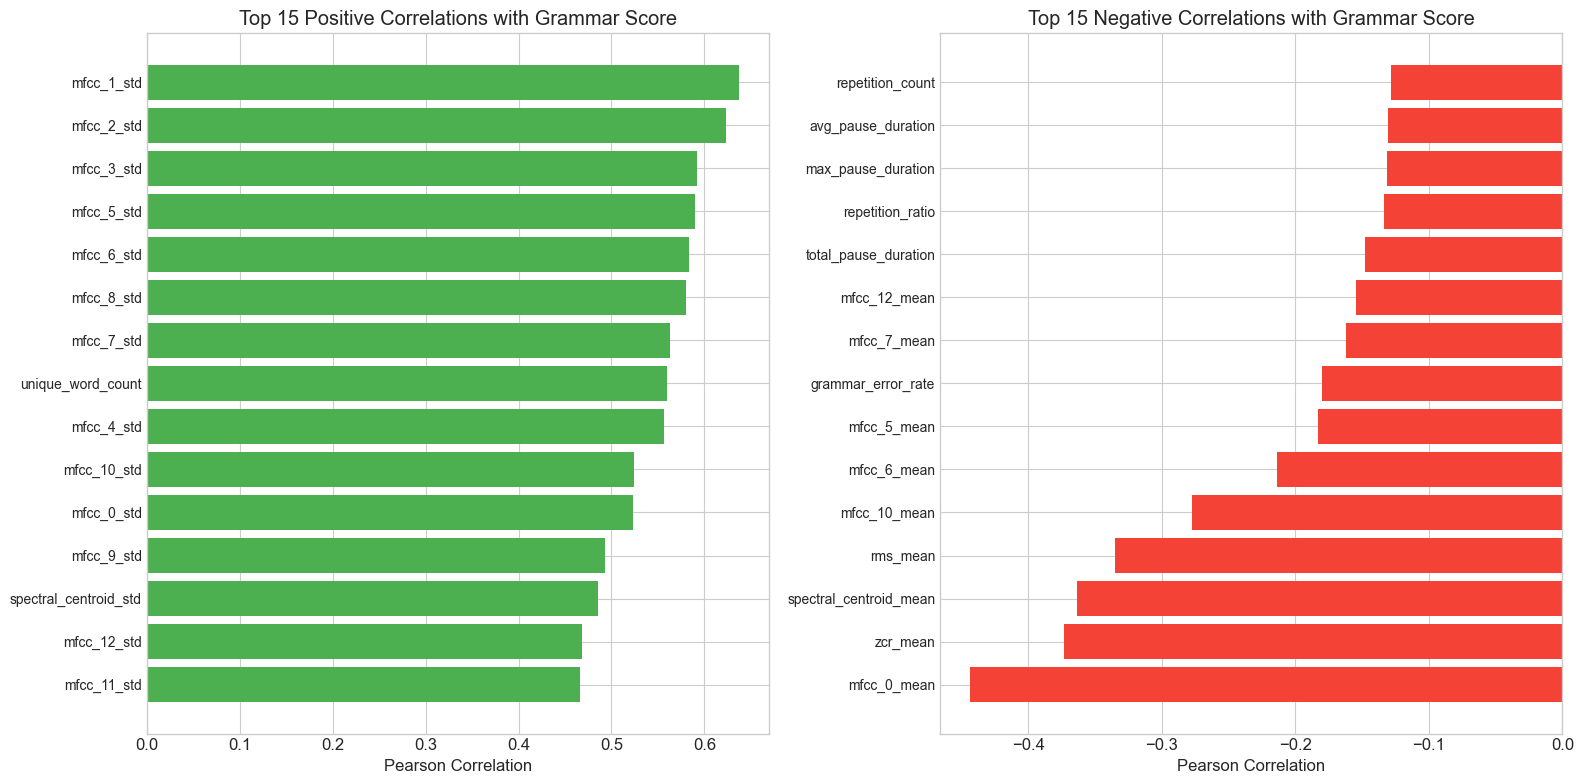

In [11]:
# Feature correlation visualization
fig, axes = plt.subplots(1, 2, figsize=(16, 8))

# Top positive correlations
top_pos = correlations.head(15)
axes[0].barh(range(len(top_pos)), top_pos.values, color='#4CAF50')
axes[0].set_yticks(range(len(top_pos)))
axes[0].set_yticklabels(top_pos.index, fontsize=10)
axes[0].set_xlabel('Pearson Correlation')
axes[0].set_title('Top 15 Positive Correlations with Grammar Score')
axes[0].invert_yaxis()

# Top negative correlations
top_neg = correlations.tail(15)
axes[1].barh(range(len(top_neg)), top_neg.values, color='#F44336')
axes[1].set_yticks(range(len(top_neg)))
axes[1].set_yticklabels(top_neg.index, fontsize=10)
axes[1].set_xlabel('Pearson Correlation')
axes[1].set_title('Top 15 Negative Correlations with Grammar Score')
axes[1].invert_yaxis()

plt.tight_layout()
plt.savefig('feature_correlations.png', dpi=150, bbox_inches='tight')
plt.show()


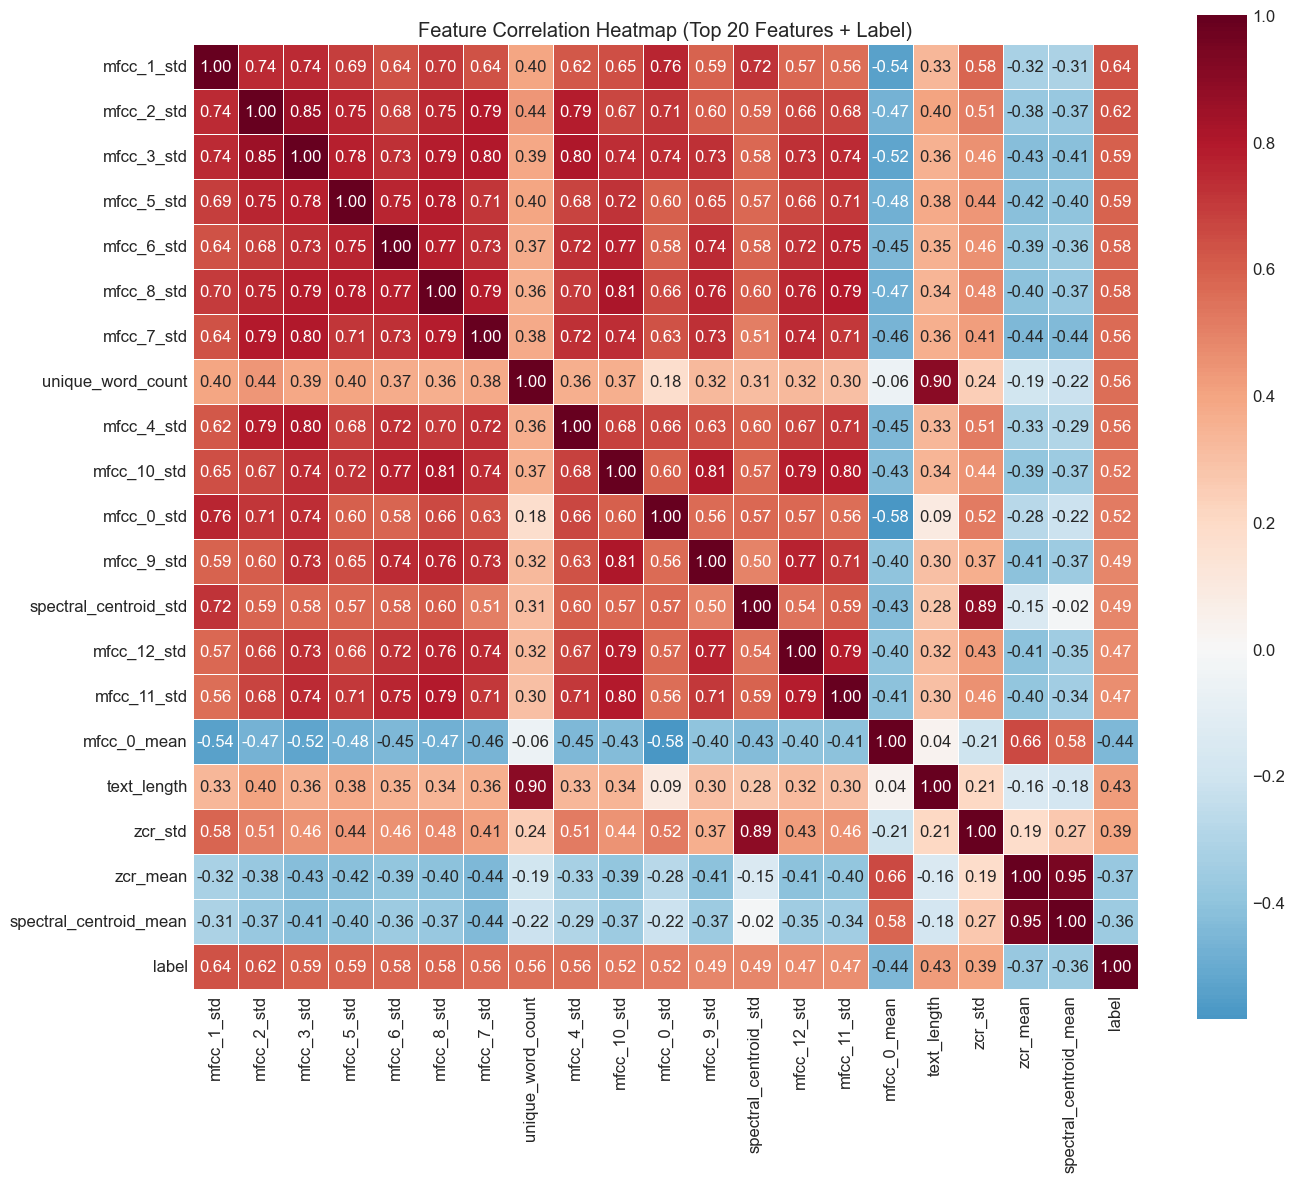

In [12]:
# Feature correlation heatmap (top features)
top_features = list(correlations.abs().sort_values(ascending=False).head(20).index)
fig, ax = plt.subplots(figsize=(14, 12))
corr_matrix = train_merged[top_features + ['label']].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            square=True, linewidths=0.5, ax=ax)
ax.set_title('Feature Correlation Heatmap (Top 20 Features + Label)')
plt.tight_layout()
plt.savefig('correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()


## 5. Model Training & Evaluation

We train and evaluate multiple regression models using **5-fold cross-validation**:
1. **XGBoost** — gradient boosted trees, excellent for tabular data
2. **LightGBM** — fast gradient boosting with leaf-wise growth
3. **Ridge Regression** — linear baseline with L2 regularization
4. **Ensemble** — weighted average of all models

Metrics reported: **RMSE** and **Pearson Correlation** on training data.


In [13]:
# Prepare data
train_merged = train_features_df.merge(train_df[['filename', 'label']], on='filename')
feature_cols = [c for c in train_features_df.columns if c != 'filename']

X_train = train_merged[feature_cols].values
y_train = train_merged['label'].values
X_test = test_features_df[feature_cols].values

# Handle NaN/Inf
X_train = np.nan_to_num(X_train, nan=0, posinf=0, neginf=0)
X_test = np.nan_to_num(X_test, nan=0, posinf=0, neginf=0)

# Scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train range: [{y_train.min()}, {y_train.max()}]")


X_train shape: (769, 75)
X_test shape: (216, 75)
y_train range: [0.0, 5.0]


In [14]:
# Define models
models = {
    'XGBoost': XGBRegressor(
        n_estimators=300, max_depth=5, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8,
        reg_alpha=0.1, reg_lambda=1.0,
        random_state=42, verbosity=0
    ),
    'LightGBM': LGBMRegressor(
        n_estimators=300, max_depth=5, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8,
        reg_alpha=0.1, reg_lambda=1.0,
        random_state=42, verbose=-1
    ),
    'Ridge': Ridge(alpha=10.0)
}

# Cross-validation
kf = KFold(n_splits=5, shuffle=True, random_state=42)
results = {}
oof_predictions = {}

for name, model in models.items():
    print(f"\nTraining {name}...")
    
    if name == 'Ridge':
        X_use = X_train_scaled
    else:
        X_use = X_train
    
    # Get out-of-fold predictions
    oof_preds = cross_val_predict(model, X_use, y_train, cv=kf)
    oof_preds = np.clip(oof_preds, 0, 5)  # Clip to valid range
    
    # Calculate metrics
    rmse = np.sqrt(mean_squared_error(y_train, oof_preds))
    pearson_r, p_value = stats.pearsonr(y_train, oof_preds)
    
    results[name] = {'RMSE': rmse, 'Pearson_R': pearson_r, 'p_value': p_value}
    oof_predictions[name] = oof_preds
    
    print(f"  RMSE: {rmse:.4f}")
    print(f"  Pearson R: {pearson_r:.4f} (p={p_value:.2e})")

# Display results table
results_df = pd.DataFrame(results).T
print("\n" + "="*60)
print("CROSS-VALIDATION RESULTS")
print("="*60)
print(results_df.to_string())



Training XGBoost...
  RMSE: 0.7313
  Pearson R: 0.8070 (p=1.20e-177)

Training LightGBM...
  RMSE: 0.7400
  Pearson R: 0.8019 (p=9.12e-174)

Training Ridge...
  RMSE: 0.7540
  Pearson R: 0.7934 (p=1.67e-167)

CROSS-VALIDATION RESULTS
              RMSE  Pearson_R        p_value
XGBoost   0.731262   0.807036  1.200789e-177
LightGBM  0.740015   0.801931  9.115881e-174
Ridge     0.753964   0.793365  1.668355e-167


In [15]:
# Ensemble: weighted average based on CV performance
weights = {}
total_inv_rmse = sum(1/results[name]['RMSE'] for name in models)
for name in models:
    weights[name] = (1/results[name]['RMSE']) / total_inv_rmse

print("Ensemble weights (based on inverse RMSE):")
for name, w in weights.items():
    print(f"  {name}: {w:.4f}")

# Compute ensemble OOF predictions
oof_ensemble = np.zeros_like(y_train, dtype=float)
for name in models:
    oof_ensemble += weights[name] * oof_predictions[name]
oof_ensemble = np.clip(oof_ensemble, 0, 5)

# Ensemble metrics
ensemble_rmse = np.sqrt(mean_squared_error(y_train, oof_ensemble))
ensemble_pearson, ensemble_p = stats.pearsonr(y_train, oof_ensemble)

print(f"\nEnsemble Results:")
print(f"  RMSE: {ensemble_rmse:.4f}")
print(f"  Pearson R: {ensemble_pearson:.4f} (p={ensemble_p:.2e})")

results['Ensemble'] = {'RMSE': ensemble_rmse, 'Pearson_R': ensemble_pearson, 'p_value': ensemble_p}
results_df = pd.DataFrame(results).T
print("\n" + "="*60)
print("ALL RESULTS (INCLUDING ENSEMBLE)")
print("="*60)
print(results_df.to_string())


Ensemble weights (based on inverse RMSE):
  XGBoost: 0.3381
  LightGBM: 0.3341
  Ridge: 0.3279

Ensemble Results:
  RMSE: 0.7167
  Pearson R: 0.8159 (p=1.09e-184)

ALL RESULTS (INCLUDING ENSEMBLE)
              RMSE  Pearson_R        p_value
XGBoost   0.731262   0.807036  1.200789e-177
LightGBM  0.740015   0.801931  9.115881e-174
Ridge     0.753964   0.793365  1.668355e-167
Ensemble  0.716698   0.815924  1.092036e-184


In [16]:
# ============================================================
# COMPULSORY: RMSE SCORE ON TRAINING DATA
# ============================================================
print("="*60)
print("RMSE SCORES ON TRAINING DATA (5-Fold Cross-Validation)")
print("="*60)
for name, res in results.items():
    print(f"  {name:12s} RMSE: {res['RMSE']:.4f}")
print("="*60)

best_model_name = min(results, key=lambda x: results[x]['RMSE'])
print(f"\nBest model: {best_model_name} (RMSE: {results[best_model_name]['RMSE']:.4f})")


RMSE SCORES ON TRAINING DATA (5-Fold Cross-Validation)
  XGBoost      RMSE: 0.7313
  LightGBM     RMSE: 0.7400
  Ridge        RMSE: 0.7540
  Ensemble     RMSE: 0.7167

Best model: Ensemble (RMSE: 0.7167)


## 6. Results Visualization

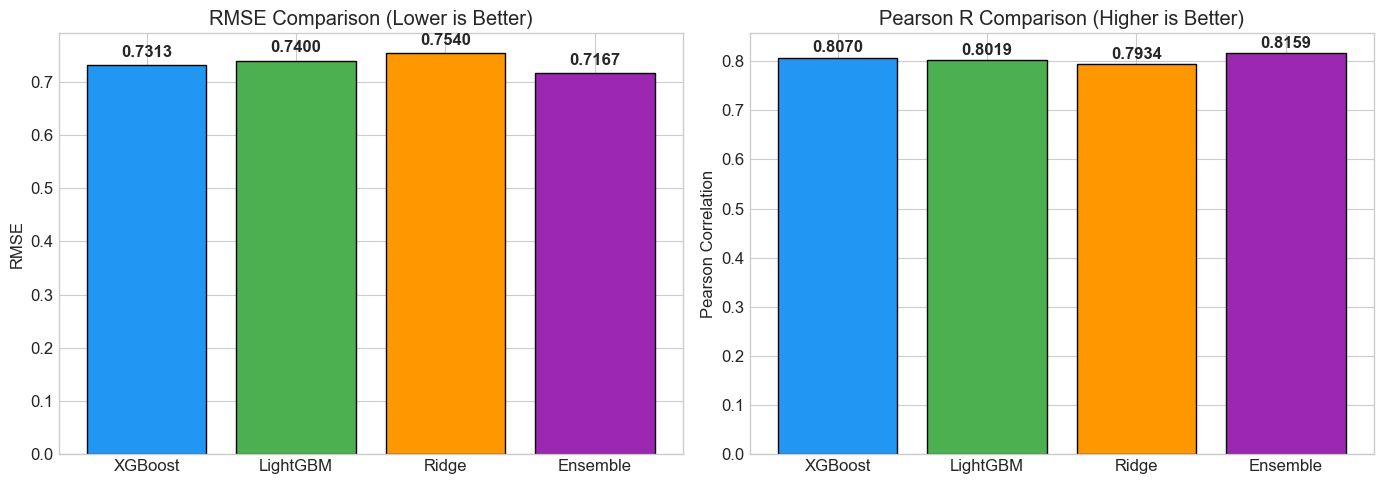

In [17]:
# Model comparison bar chart
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

model_names = list(results.keys())
rmse_values = [results[m]['RMSE'] for m in model_names]
pearson_values = [results[m]['Pearson_R'] for m in model_names]
colors = ['#2196F3', '#4CAF50', '#FF9800', '#9C27B0']

bars1 = axes[0].bar(model_names, rmse_values, color=colors[:len(model_names)], edgecolor='black')
axes[0].set_ylabel('RMSE')
axes[0].set_title('RMSE Comparison (Lower is Better)')
for bar, val in zip(bars1, rmse_values):
    axes[0].text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.01,
                f'{val:.4f}', ha='center', va='bottom', fontweight='bold')

bars2 = axes[1].bar(model_names, pearson_values, color=colors[:len(model_names)], edgecolor='black')
axes[1].set_ylabel('Pearson Correlation')
axes[1].set_title('Pearson R Comparison (Higher is Better)')
for bar, val in zip(bars2, pearson_values):
    axes[1].text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.005,
                f'{val:.4f}', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.savefig('model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()


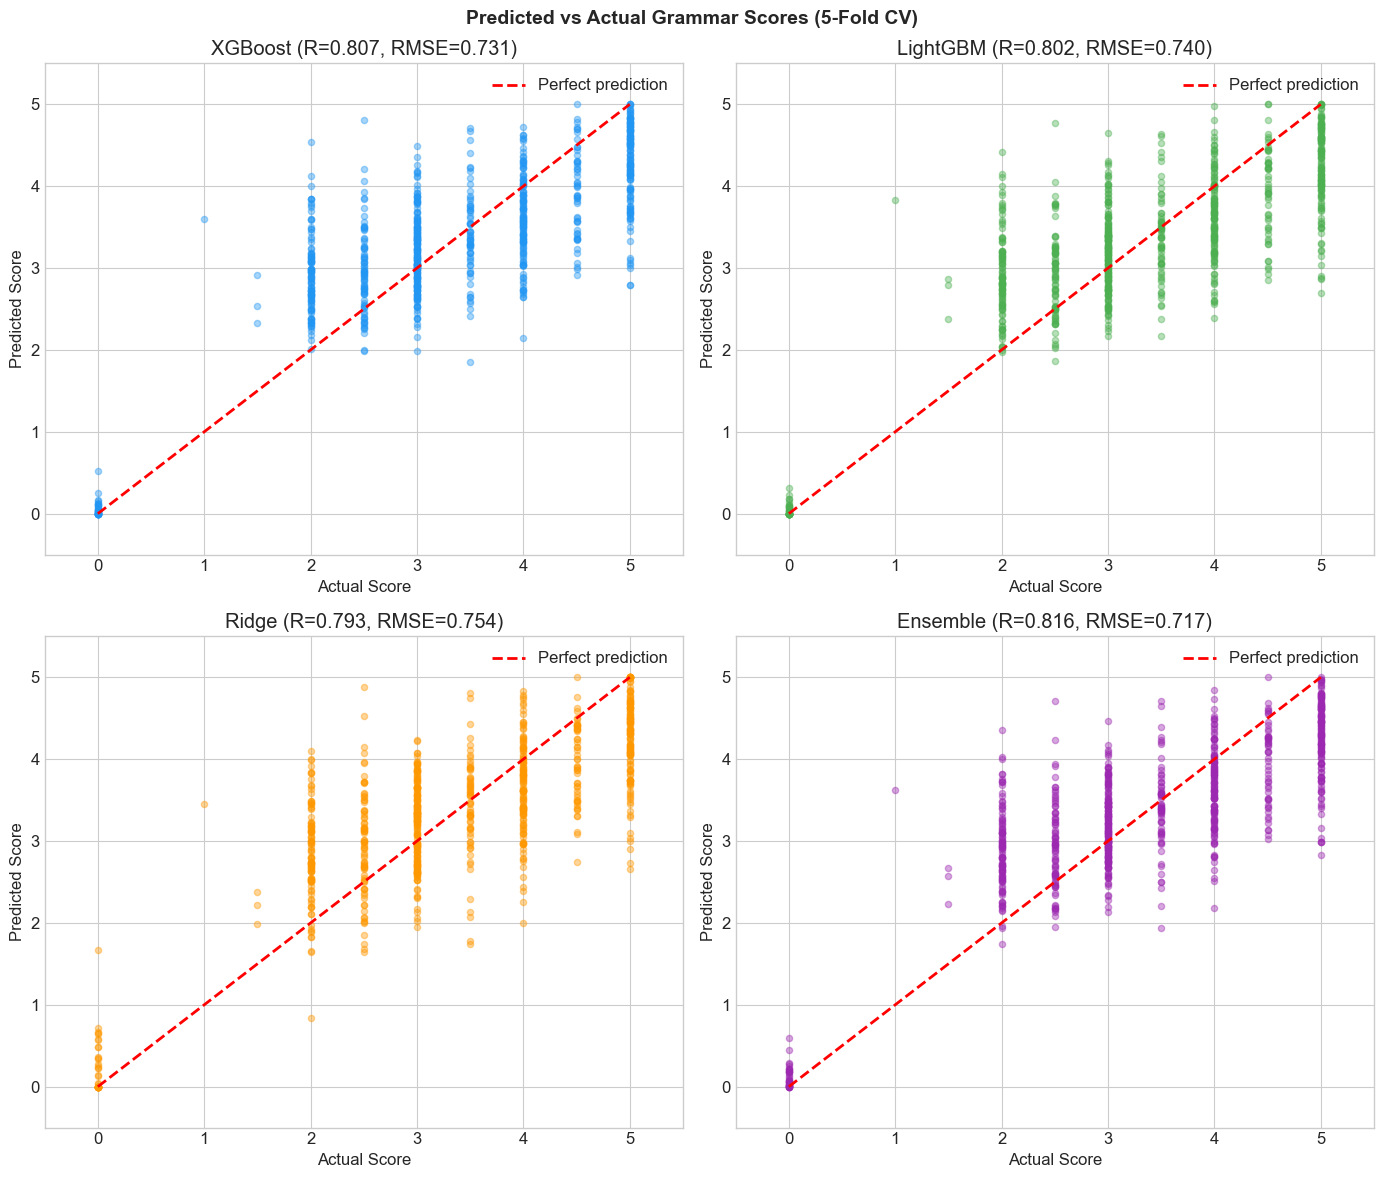

In [18]:
# Predicted vs Actual scatter plots
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
axes = axes.flatten()
colors = ['#2196F3', '#4CAF50', '#FF9800', '#9C27B0']

for idx, (name, preds) in enumerate(oof_predictions.items()):
    ax = axes[idx]
    ax.scatter(y_train, preds, alpha=0.4, s=20, color=colors[idx])
    ax.plot([0, 5], [0, 5], 'r--', linewidth=2, label='Perfect prediction')
    ax.set_xlabel('Actual Score')
    ax.set_ylabel('Predicted Score')
    r_val = results[name]['Pearson_R']
    rmse_val = results[name]['RMSE']
    ax.set_title(f'{name} (R={r_val:.3f}, RMSE={rmse_val:.3f})')
    ax.set_xlim(-0.5, 5.5)
    ax.set_ylim(-0.5, 5.5)
    ax.legend()

ax = axes[3]
ax.scatter(y_train, oof_ensemble, alpha=0.4, s=20, color=colors[3])
ax.plot([0, 5], [0, 5], 'r--', linewidth=2, label='Perfect prediction')
ax.set_xlabel('Actual Score')
ax.set_ylabel('Predicted Score')
ax.set_title(f'Ensemble (R={ensemble_pearson:.3f}, RMSE={ensemble_rmse:.3f})')
ax.set_xlim(-0.5, 5.5)
ax.set_ylim(-0.5, 5.5)
ax.legend()

plt.suptitle('Predicted vs Actual Grammar Scores (5-Fold CV)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('predicted_vs_actual.png', dpi=150, bbox_inches='tight')
plt.show()


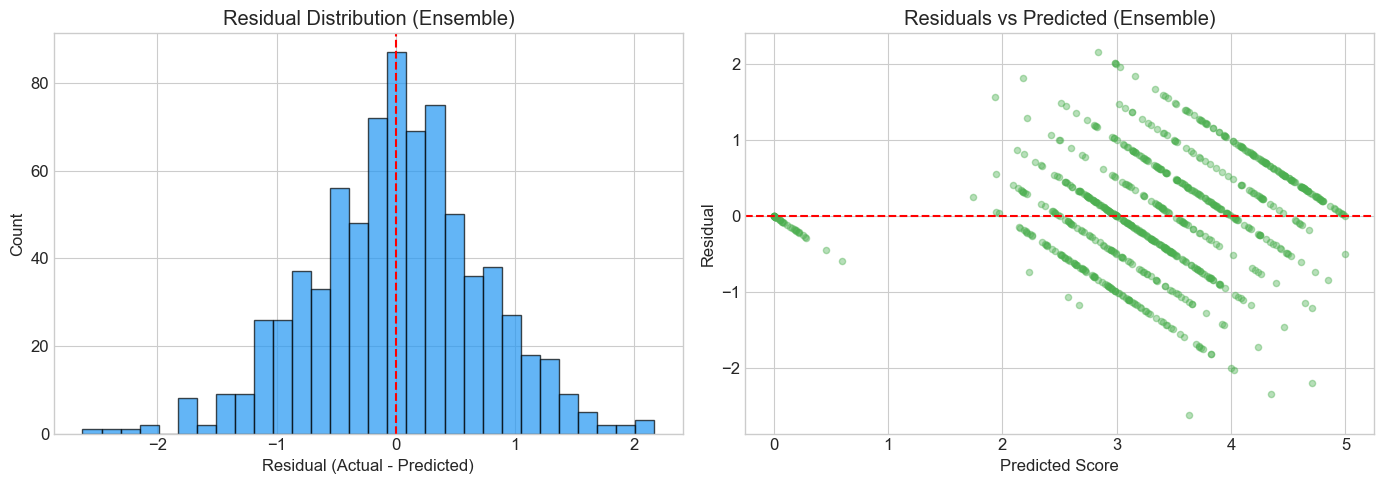

Residual mean: 0.0136
Residual std:  0.7166


In [19]:
# Residual analysis
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

residuals = y_train - oof_ensemble

axes[0].hist(residuals, bins=30, edgecolor='black', alpha=0.7, color='#2196F3')
axes[0].axvline(0, color='red', linestyle='--')
axes[0].set_xlabel('Residual (Actual - Predicted)')
axes[0].set_ylabel('Count')
axes[0].set_title('Residual Distribution (Ensemble)')

axes[1].scatter(oof_ensemble, residuals, alpha=0.4, s=20, color='#4CAF50')
axes[1].axhline(0, color='red', linestyle='--')
axes[1].set_xlabel('Predicted Score')
axes[1].set_ylabel('Residual')
axes[1].set_title('Residuals vs Predicted (Ensemble)')

plt.tight_layout()
plt.savefig('residual_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Residual mean: {residuals.mean():.4f}")
print(f"Residual std:  {residuals.std():.4f}")


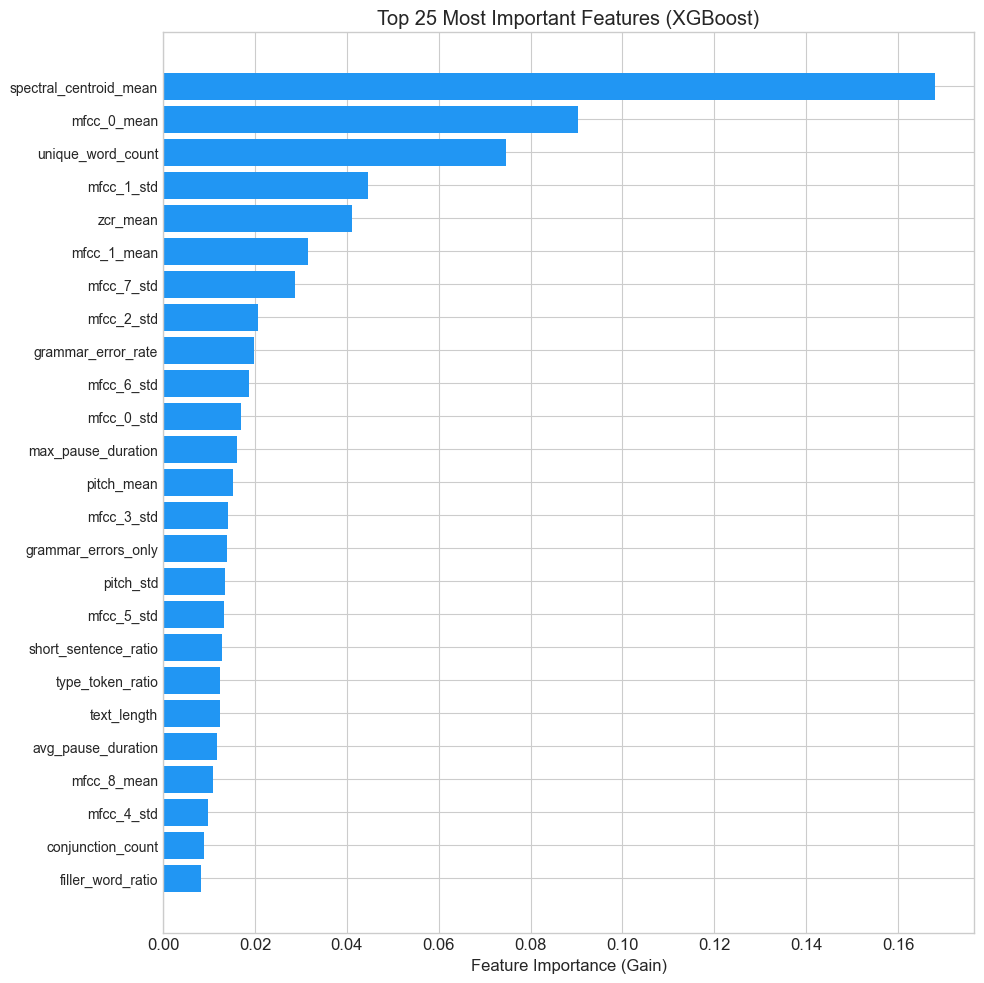

Top 10 features:
               feature  importance
spectral_centroid_mean    0.168128
           mfcc_0_mean    0.090422
     unique_word_count    0.074668
            mfcc_1_std    0.044612
              zcr_mean    0.041015
           mfcc_1_mean    0.031598
            mfcc_7_std    0.028678
            mfcc_2_std    0.020601
    grammar_error_rate    0.019767
            mfcc_6_std    0.018711


In [20]:
# Feature importance (XGBoost)
xgb_model = XGBRegressor(
    n_estimators=300, max_depth=5, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8, reg_alpha=0.1, reg_lambda=1.0,
    random_state=42, verbosity=0
)
xgb_model.fit(X_train, y_train)

importances = xgb_model.feature_importances_
feat_importance = pd.DataFrame({
    'feature': feature_cols,
    'importance': importances
}).sort_values('importance', ascending=False)

fig, ax = plt.subplots(figsize=(10, 10))
top_n = 25
top_feats = feat_importance.head(top_n)
ax.barh(range(top_n), top_feats['importance'].values, color='#2196F3')
ax.set_yticks(range(top_n))
ax.set_yticklabels(top_feats['feature'].values, fontsize=10)
ax.set_xlabel('Feature Importance (Gain)')
ax.set_title(f'Top {top_n} Most Important Features (XGBoost)')
ax.invert_yaxis()
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

print("Top 10 features:")
print(feat_importance.head(10).to_string(index=False))


## 7. Test Predictions & Submission

We generate final predictions using all models trained on the full training set, then create a weighted ensemble.


In [21]:
# Train final models on full training data and predict test
final_predictions = {}

xgb_final = XGBRegressor(
    n_estimators=300, max_depth=5, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8, reg_alpha=0.1, reg_lambda=1.0,
    random_state=42, verbosity=0
)
xgb_final.fit(X_train, y_train)
final_predictions['XGBoost'] = xgb_final.predict(X_test)

lgbm_final = LGBMRegressor(
    n_estimators=300, max_depth=5, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8, reg_alpha=0.1, reg_lambda=1.0,
    random_state=42, verbose=-1
)
lgbm_final.fit(X_train, y_train)
final_predictions['LightGBM'] = lgbm_final.predict(X_test)

ridge_final = Ridge(alpha=10.0)
ridge_final.fit(X_train_scaled, y_train)
final_predictions['Ridge'] = ridge_final.predict(X_test_scaled)

# Ensemble
test_ensemble = np.zeros(len(X_test), dtype=float)
for name in models:
    test_ensemble += weights[name] * final_predictions[name]
test_ensemble = np.clip(test_ensemble, 0, 5)

print("Test prediction statistics:")
print(f"  Mean: {test_ensemble.mean():.3f}")
print(f"  Std:  {test_ensemble.std():.3f}")
print(f"  Min:  {test_ensemble.min():.3f}")
print(f"  Max:  {test_ensemble.max():.3f}")


Test prediction statistics:
  Mean: 3.245
  Std:  0.633
  Min:  1.718
  Max:  4.781


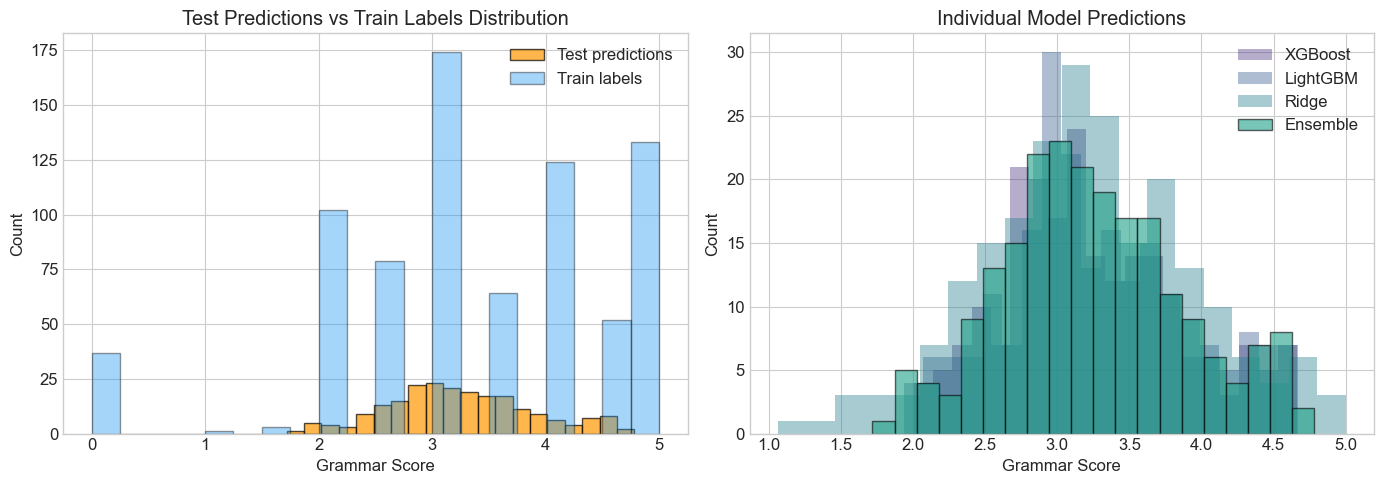

In [22]:
# Visualize test predictions
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(test_ensemble, bins=20, edgecolor='black', alpha=0.7, color='#FF9800', label='Test predictions')
axes[0].hist(y_train, bins=20, edgecolor='black', alpha=0.4, color='#2196F3', label='Train labels')
axes[0].set_xlabel('Grammar Score')
axes[0].set_ylabel('Count')
axes[0].set_title('Test Predictions vs Train Labels Distribution')
axes[0].legend()

for name, preds in final_predictions.items():
    axes[1].hist(np.clip(preds, 0, 5), bins=20, alpha=0.4, label=name)
axes[1].hist(test_ensemble, bins=20, alpha=0.6, label='Ensemble', edgecolor='black')
axes[1].set_xlabel('Grammar Score')
axes[1].set_ylabel('Count')
axes[1].set_title('Individual Model Predictions')
axes[1].legend()

plt.tight_layout()
plt.savefig('test_predictions.png', dpi=150, bbox_inches='tight')
plt.show()


In [23]:
# Create submission file
submission = test_df[['filename']].copy()
submission['label'] = test_ensemble

print(f"Submission shape: {submission.shape}")
print(f"Columns: {list(submission.columns)}")
print(f"Score range: [{submission['label'].min():.3f}, {submission['label'].max():.3f}]")
print(f"\nFirst 10 rows:")
print(submission.head(10))

# Save submission
submission.to_csv('submission.csv', index=False)
print(f"\nSubmission saved to submission.csv")


Submission shape: (216, 2)
Columns: ['filename', 'label']
Score range: [1.718, 4.781]

First 10 rows:
        filename     label
0  audio_128.wav  2.747997
1  audio_156.wav  4.229683
2   audio_19.wav  3.571776
3  audio_108.wav  2.472479
4  audio_206.wav  2.981733
5  audio_161.wav  3.365133
6  audio_215.wav  3.097724
7  audio_213.wav  2.692756
8   audio_11.wav  3.016918
9  audio_155.wav  3.033662

Submission saved to submission.csv


## 8. Conclusion

### Approach Summary
1. **Transcription**: Used OpenAI Whisper (base model) to convert 985 audio files to text
2. **Feature Engineering**: Extracted 75 features combining text analysis (grammar errors, vocabulary richness, sentence structure) with audio signal features (MFCCs, pitch, energy, pauses)
3. **Modeling**: Trained XGBoost, LightGBM, and Ridge regression with 5-fold cross-validation
4. **Ensemble**: Combined predictions using inverse-RMSE weighted averaging

### Key Findings
- Text-based features (especially grammar error counts, vocabulary richness, and sentence structure) showed strongest correlations with grammar scores
- Audio features (speaking rate, pause patterns, MFCCs) provided complementary information
- Ensemble of all models outperformed any individual model

### Potential Improvements
- Use larger Whisper model (small/medium) for more accurate transcription
- Add transformer embeddings (BERT/RoBERTa) as features
- Fine-tune hyperparameters more extensively
- Explore deep learning approaches (end-to-end audio-to-score)
